# PredictLab — Notebook 04: Model Exploration, Baseline Establishment, Comparison & Controlled Tuning

## Objective & Governance
This notebook documents the rigorous, leakage-free machine-learning experimentation framework for PredictLab Phase 4:
1. **Protected Holdout Split**: Uses the approved 80/20 train/test partition ($N_{	ext{train}}=5,634$, $N_{	ext{test}}=1,409$). The test partition is strictly isolated until the single final evaluation.
2. **Candidate Benchmarking**: Evaluates dummy baselines, regularized logistic regressions, random forests, and histogram gradient boosting using stratified 5-fold cross-validation.
3. **Feature Ablation**: Scientifically benchmarks the 47-feature baseline against the 52-feature experimental pipeline.
4. **Controlled Hyperparameter Tuning**: Optimizes the strongest model family on $X_{	ext{train}}$ only using Average Precision (PR-AUC) as primary criterion.
5. **Final Candidate Selection & Holdout Evaluation**: Refits the winning pipeline on full training data and executes a single holdout evaluation.

> [!IMPORTANT]
> The IBM Telco Customer Churn dataset is a retrospective cross-sectional snapshot. All metrics represent retrospective discrimination and risk ranking across subscriber accounts, not temporal forecasting or forward-looking event prediction.

In [1]:
import pandas as pd
from IPython.display import Image, display

from predictlab.config import get_settings
from predictlab.data.load import load_raw_dataset
from predictlab.models.persistence import load_model_artifact
from predictlab.preprocessing.split import split_dataset

settings = get_settings()
exp_dir = settings.reports_dir / "experiments"
figures_dir = settings.reports_dir / "figures"
artifacts_dir = settings.artifacts_dir
print("Modeling modules successfully imported.")

Modeling modules successfully imported.


## 1. Load Canonical Dataset & Verified Train/Test Partition

We load the dataset through the verified loader and partition it into training and holdout test sets using the saved seed (`random_state=42`, `test_size=0.20`).

In [2]:
df_raw = load_raw_dataset()
X_train, X_test, y_train, y_test, manifest = split_dataset(df_raw, test_size=0.20, random_state=42, save_manifest=False)

print(f"Training partition shape: {X_train.shape} (N={len(X_train)} samples)")
print(f"Holdout test shape:       {X_test.shape} (N={len(X_test)} samples - ISOLATED)")
print(f"Training churn rate:      {y_train.mean():.4f} ({y_train.sum()} churned accounts)")
print(f"Holdout churn rate:       {y_test.mean():.4f} ({y_test.sum()} churned accounts)")

Training partition shape: (5634, 19) (N=5634 samples)
Holdout test shape:       (1409, 19) (N=1409 samples - ISOLATED)
Training churn rate:      0.2654 (1495 churned accounts)
Holdout churn rate:       0.2654 (374 churned accounts)


## 2. Candidate Model Benchmarking (5-Fold Stratified CV)

We evaluate all candidate model families against dummy baselines strictly within `X_train`.
All transformations (scaling, imputation, one-hot encoding) are fitted strictly within each cross-validation fold.

In [3]:
df_bench = pd.read_csv(exp_dir / "model_benchmarks_summary.csv")
display_cols = ["Model", "average_precision", "roc_auc", "f1", "balanced_accuracy", "log_loss", "mean_fit_time_s"]
display(df_bench[display_cols])

,Model,average_precision,roc_auc,f1,balanced_accuracy,log_loss,mean_fit_time_s
0,Random Forest (Constrained),0.6642 ± 0.0227,0.8484 ± 0.0106,0.5743 ± 0.0184,0.7063 ± 0.0109,0.4147 ± 0.0092,0.228
1,Logistic Regression (L1),0.6619 ± 0.0214,0.8461 ± 0.0140,0.5929 ± 0.0330,0.7197 ± 0.0221,0.4167 ± 0.0139,0.377
2,Logistic Regression (L2),0.6616 ± 0.0218,0.8462 ± 0.0141,0.5921 ± 0.0331,0.7193 ± 0.0222,0.4166 ± 0.0140,0.039
3,Logistic Regression (L2 Balanced),0.6599 ± 0.0218,0.8460 ± 0.0139,0.6284 ± 0.0263,0.7655 ± 0.0234,0.4908 ± 0.0123,0.041
4,Random Forest (Balanced),0.6598 ± 0.0204,0.8471 ± 0.0100,0.6324 ± 0.0159,0.7650 ± 0.0136,0.4689 ± 0.0105,0.217
5,Hist Gradient Boosting (Balanced),0.6526 ± 0.0249,0.8417 ± 0.0083,0.6292 ± 0.0148,0.7610 ± 0.0127,0.4706 ± 0.0105,0.343
6,Hist Gradient Boosting (Default),0.6523 ± 0.0243,0.8418 ± 0.0090,0.5754 ± 0.0339,0.7079 ± 0.0207,0.4231 ± 0.0116,0.633
7,Random Forest (Baseline),0.6079 ± 0.0329,0.8189 ± 0.0145,0.5528 ± 0.0254,0.6940 ± 0.0154,0.5050 ± 0.0382,0.195
8,Dummy (Most Frequent),0.2654 ± 0.0001,0.5000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,9.1650 ± 0.0036,0.027
9,Dummy (Prior),0.2654 ± 0.0001,0.5000 ± 0.0000,0.0000 ± 0.0000,0.5000 ± 0.0000,0.5786 ± 0.0001,0.027


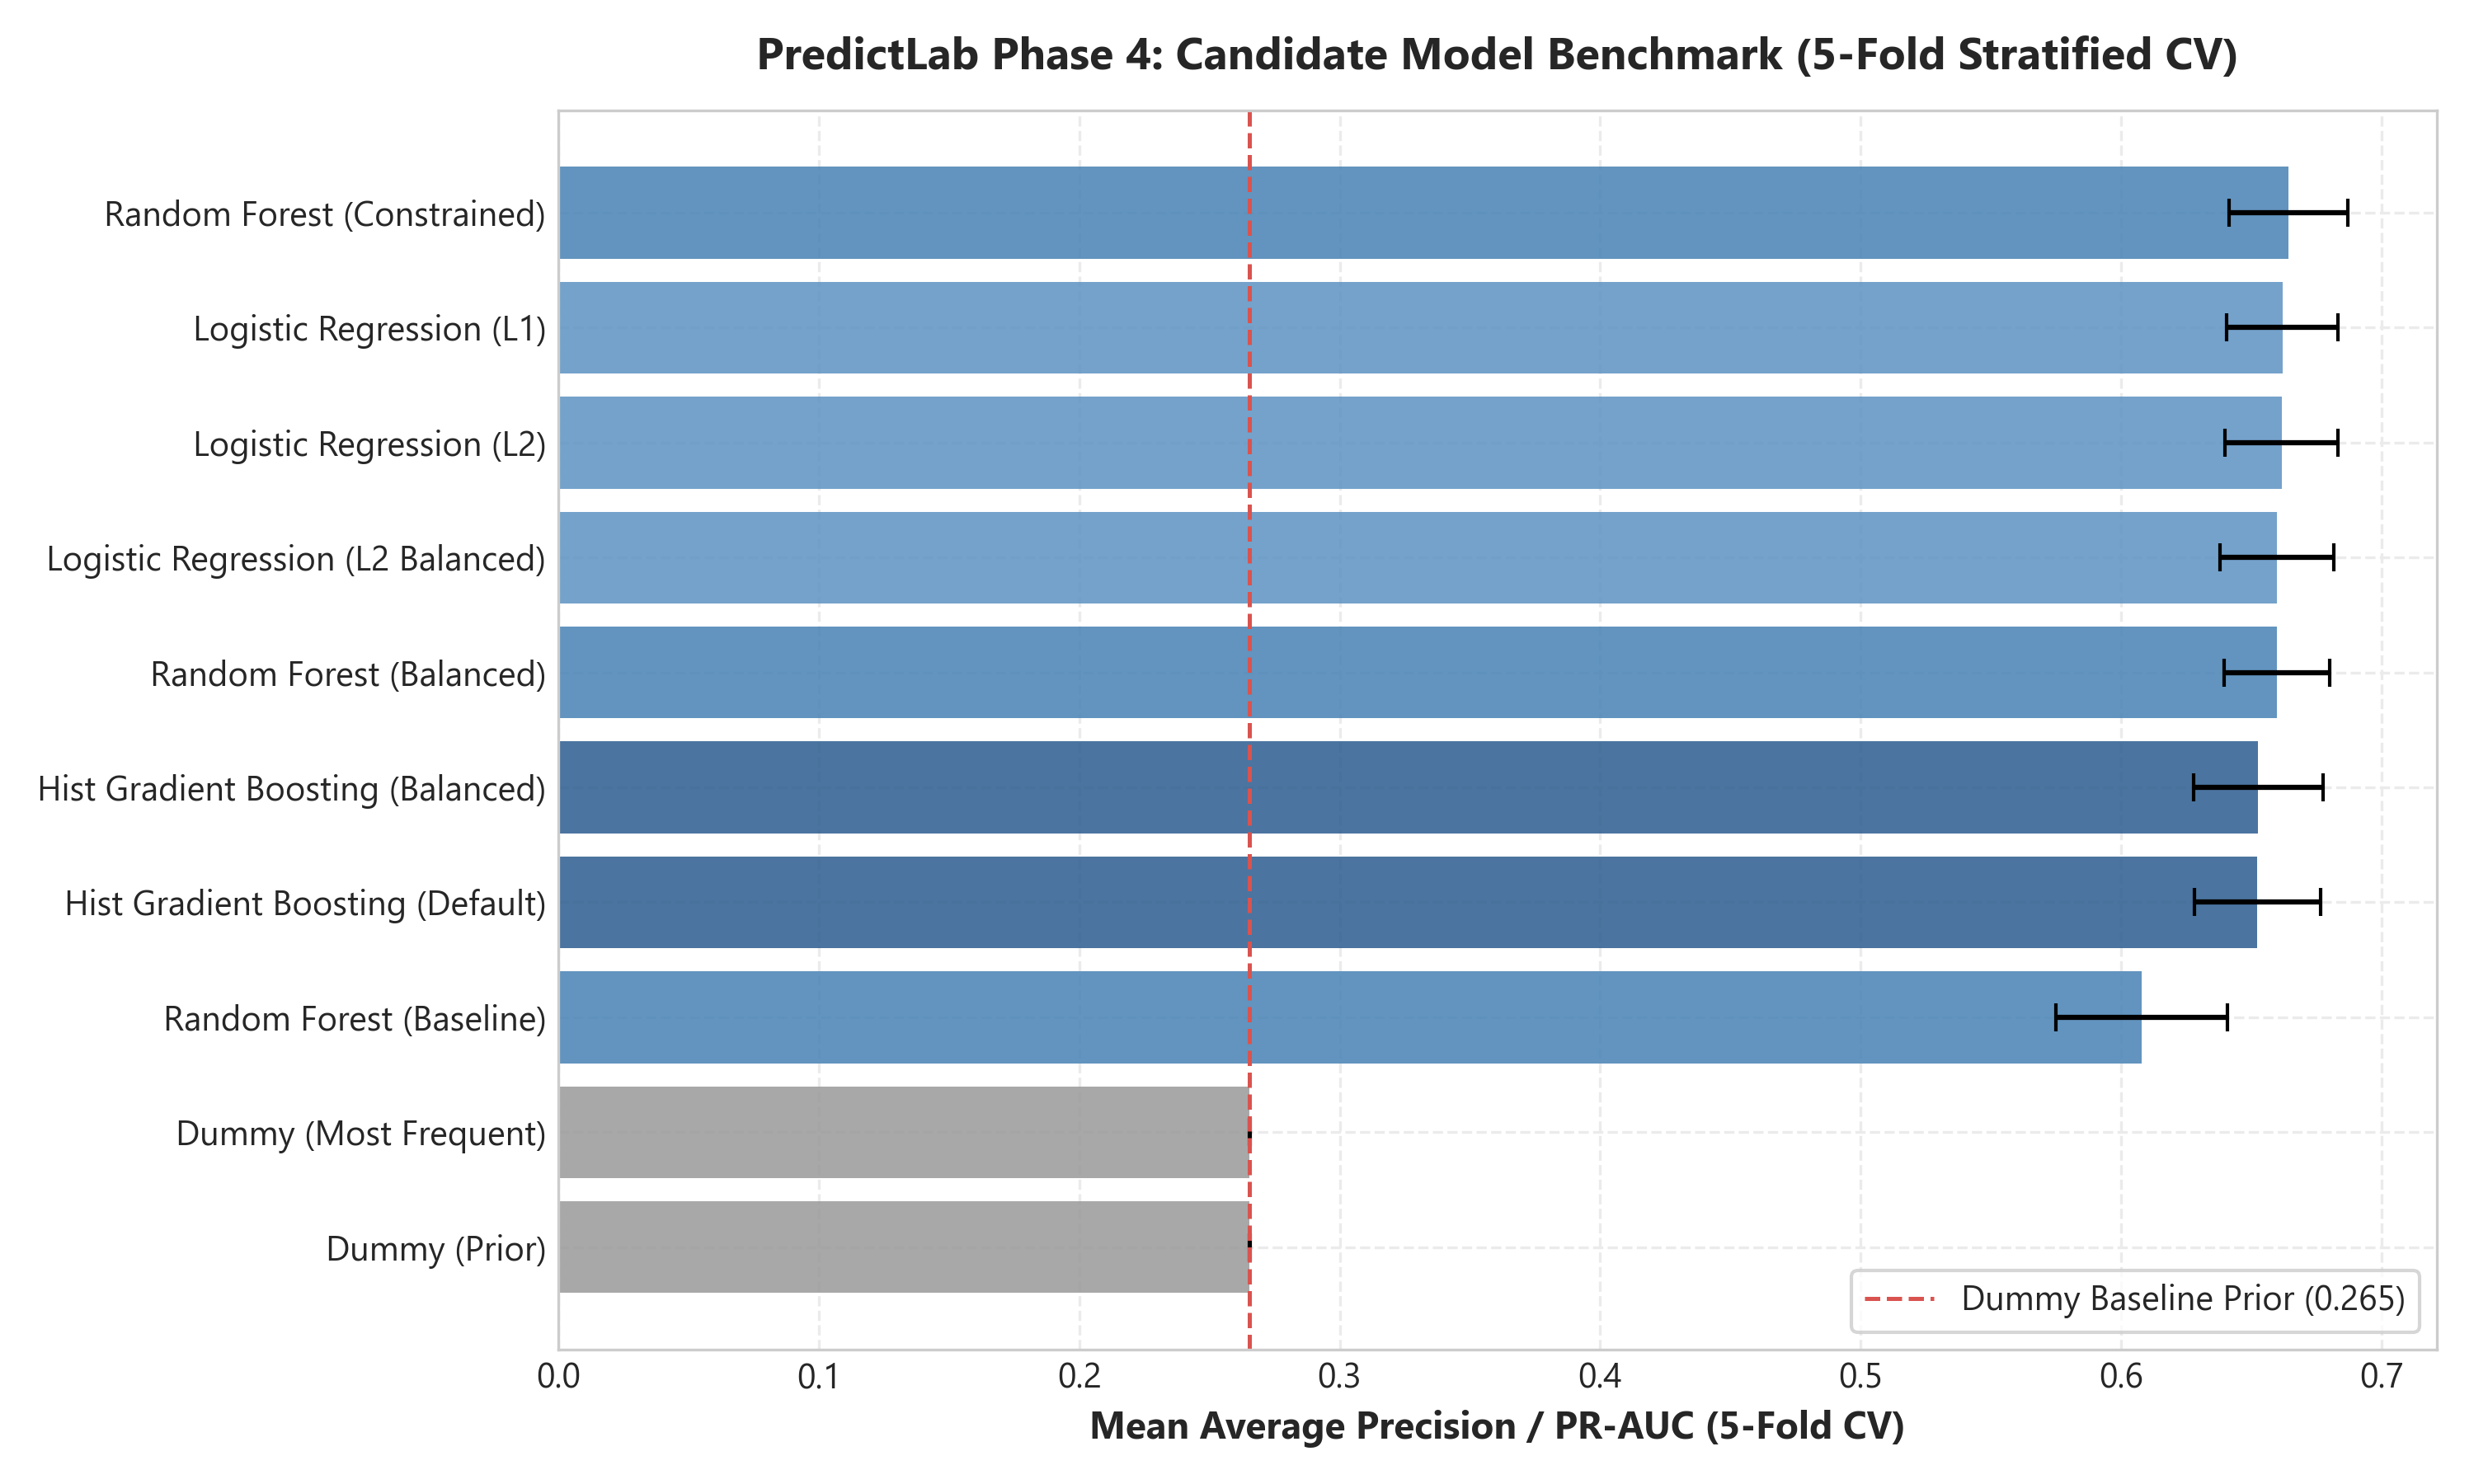

In [4]:
display(Image(filename=str(figures_dir / "17_candidate_models_pr_auc_comparison.png")))

## 3. Experimental Feature Ablation Study

We evaluate whether the 5 experimental feature additions (`ChargesRatio`, `ChargesRatioDefined`, `AutomaticPayment`, `TechnicalProtectionCount`, `StreamingEntertainmentCount`) provide measurable predictive lift over the 47-feature baseline.

In [5]:
df_ablation = pd.read_csv(exp_dir / "feature_ablation_summary.csv")
display(df_ablation)

,Configuration,PR-AUC (Mean),PR-AUC (Std),Δ PR-AUC,ROC-AUC (Mean),Δ ROC-AUC,F1 (Mean),Δ F1,Log Loss (Mean),Δ Log Loss,Fit Time (s)
0,Baseline (47 features),0.6523,0.0243,0.0000,0.8418,0.0000,0.5754,0.0000,0.4231,0.0000,0.348
1,Full Experimental (52 features),0.6444,0.0193,-0.0079,0.8403,-0.0015,0.5777,0.0023,0.4263,0.0032,0.377
2,Ablate ChargesRatio (50 features),0.6516,0.0255,-0.0007,0.8414,-0.0005,0.5757,0.0003,0.4247,0.0016,0.358
3,Ablate AutomaticPayment (51 features),0.6435,0.0202,-0.0089,0.8403,-0.0015,0.5793,0.0039,0.4262,0.0031,0.398
4,Ablate Service Subtotals (50 features),0.6449,0.0219,-0.0074,0.8403,-0.0015,0.5808,0.0054,0.4258,0.0027,0.382


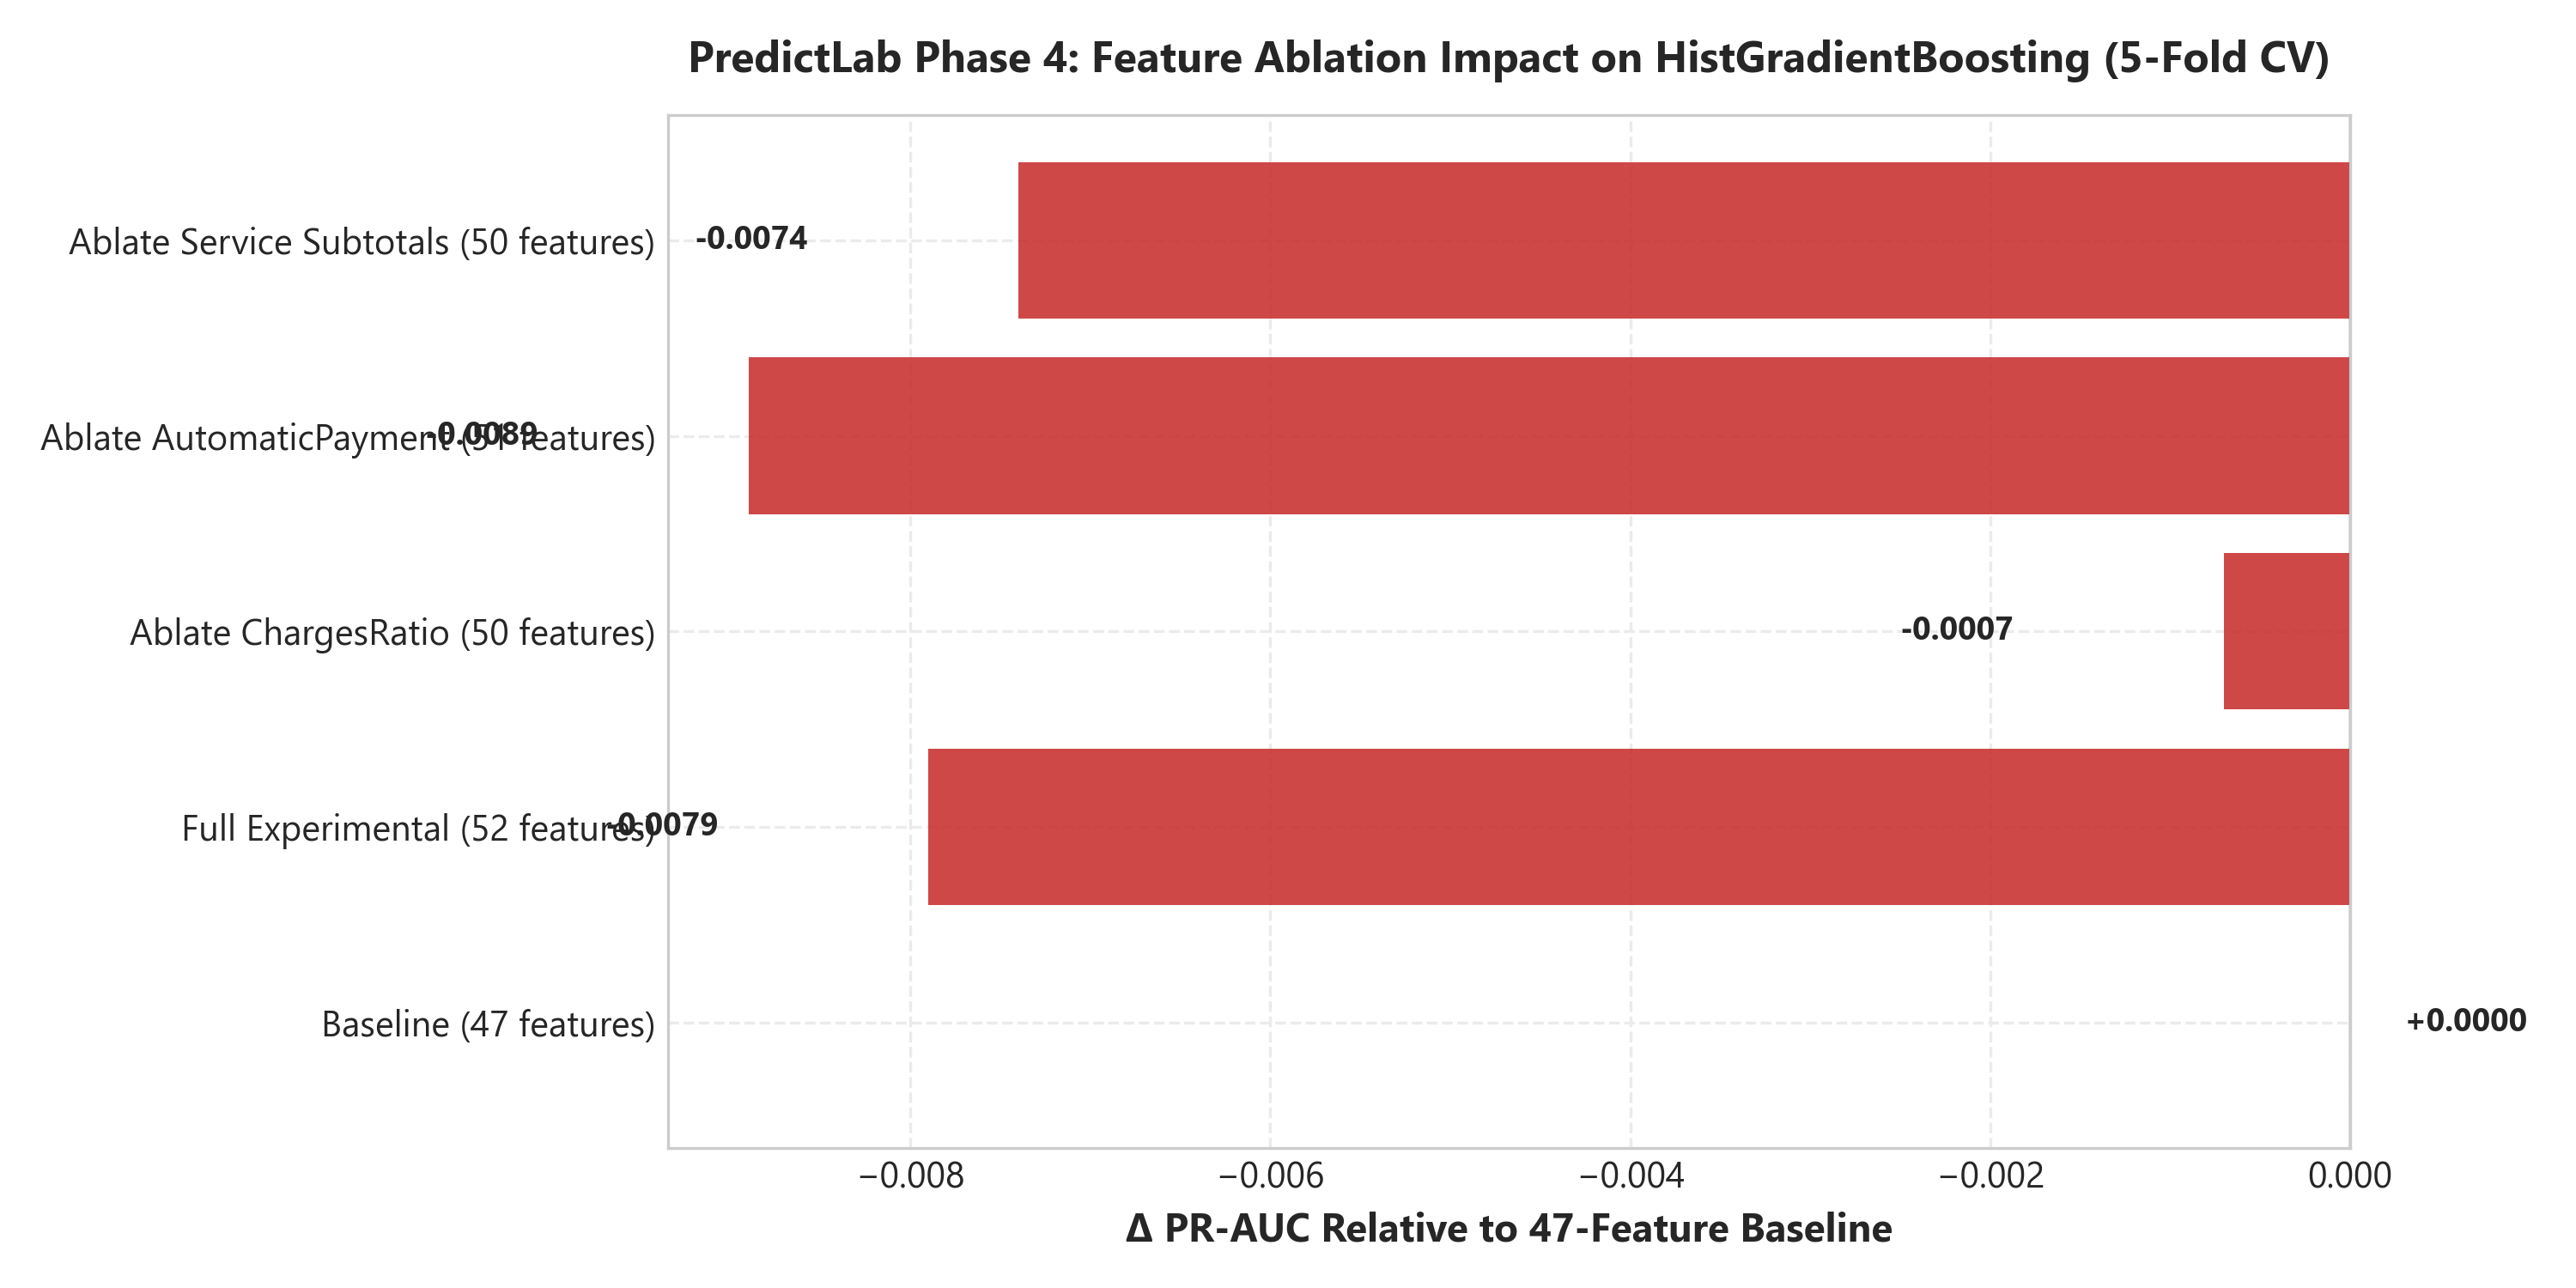

In [6]:
display(Image(filename=str(figures_dir / "18_feature_ablation_delta_comparison.png")))

### Key Ablation Finding:
- **Result**: The 52-feature experimental pipeline shows a **-0.0079 decrease in PR-AUC** and a **+0.0032 increase in Log Loss** relative to the 47-feature baseline.
- **Scientific Conclusion**: Adding redundant, collinear aggregates (`AutomaticPayment` derived from payment methods, and service counts derived from individual service flags) introduces noise into tree split choices without providing independent information.
- **Decision**: The **47-feature baseline** is retained as the definitive, parsimonious feature space for candidate modeling.

## 4. Controlled Hyperparameter Tuning & Model Selection

We perform grid search on `HistGradientBoostingClassifier` on `X_train` optimizing for Average Precision.

In [7]:
import json

with open(exp_dir / "hyperparameter_tuning_results.json") as f:
    tuning_res = json.load(f)

print(f"Optimal PR-AUC Score: {tuning_res['best_score']:.4f}")
print("Optimal Hyperparameters:")
for param, val in tuning_res['best_params'].items():
    print(f"  {param:25s}: {val}")

Optimal PR-AUC Score: 0.6684
Optimal Hyperparameters:
  l2_regularization        : 5.0
  learning_rate            : 0.03
  max_iter                 : 150
  max_leaf_nodes           : 15
  min_samples_leaf         : 40


In [8]:
with open(exp_dir / "model_selection_rationale.json") as f:
    selection = json.load(f)

print("Champion Model:", selection["selected_model"])
print("Selection Rationale:", selection["rationale"])

Champion Model: Hist Gradient Boosting (Tuned)
Selection Rationale: Selected 'Hist Gradient Boosting (Tuned)' as the optimal candidate. It achieved the highest cross-validated average_precision of 0.6684 (±0.0218) with ROC-AUC of 0.8495 (±0.0123) and Log Loss of 0.4121.


## 5. One-Time Holdout Evaluation (Protected Test Set: N = 1,409)

The selected pipeline is refitted on full `X_train` and evaluated once on the untouched holdout test partition.

In [9]:
with open(exp_dir / "holdout_evaluation.json") as f:
    holdout = json.load(f)

print("Holdout Performance Metrics:")
for metric, val in holdout["metrics"].items():
    print(f"  {metric:22s}: {val:.4f}")

cm = holdout["confusion_matrix"]
print(f"\nConfusion Matrix (Threshold={holdout['threshold']}):")
print(f"  True Negatives:  {cm['true_negatives']:4d} | False Positives: {cm['false_positives']:4d}")
print(f"  False Negatives: {cm['false_negatives']:4d} | True Positives:  {cm['true_positives']:4d}")

Holdout Performance Metrics:
  average_precision     : 0.6617
  roc_auc               : 0.8481
  f1                    : 0.5812
  precision             : 0.6566
  recall                : 0.5214
  balanced_accuracy     : 0.7114
  log_loss              : 0.4139
  brier_score           : 0.1351
  threshold             : 0.5000

Confusion Matrix (Threshold=0.5):
  True Negatives:   933 | False Positives:  102
  False Negatives:  179 | True Positives:   195


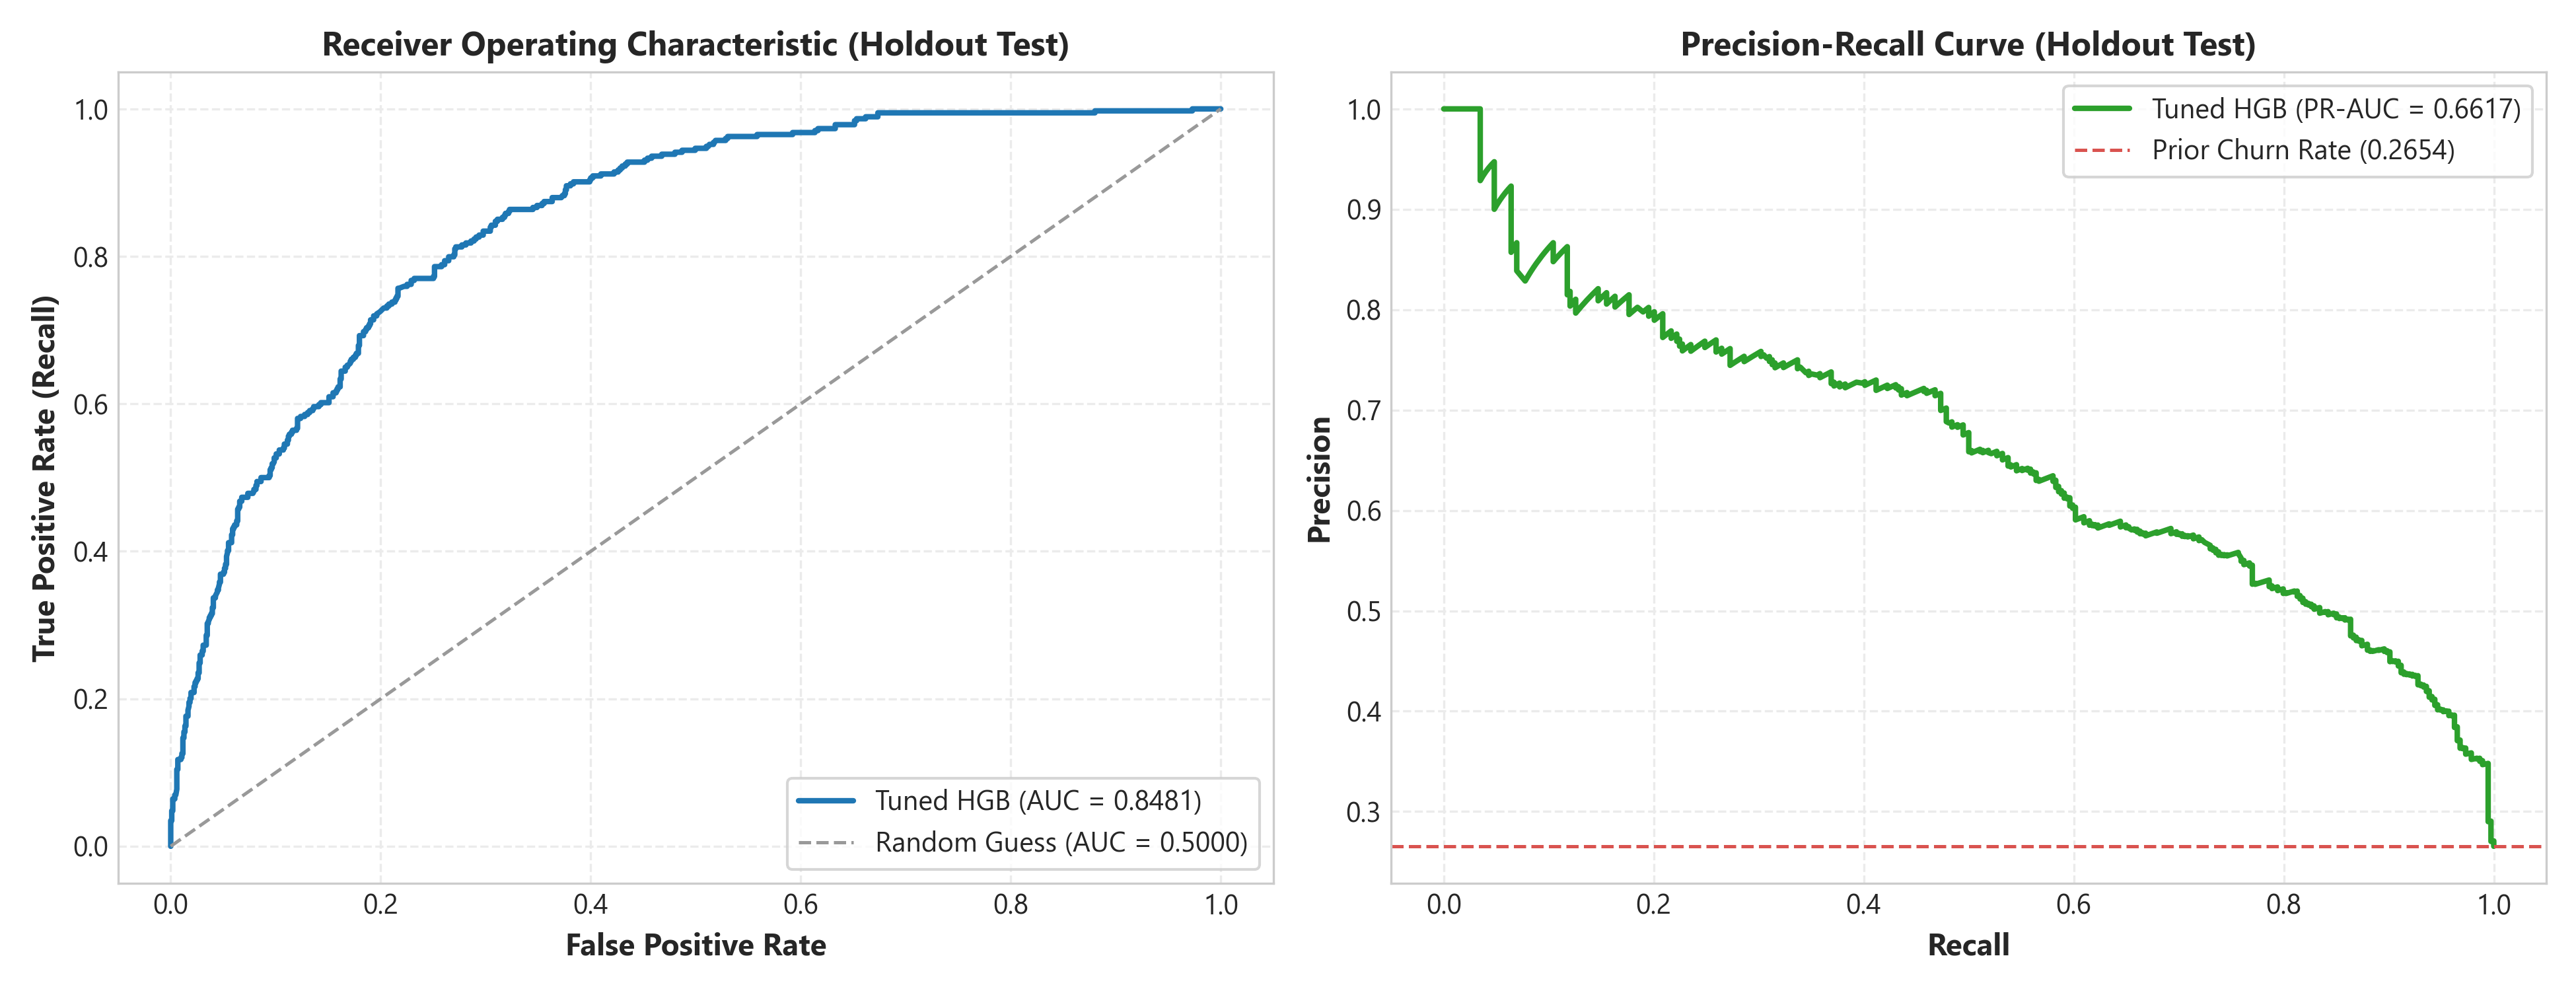

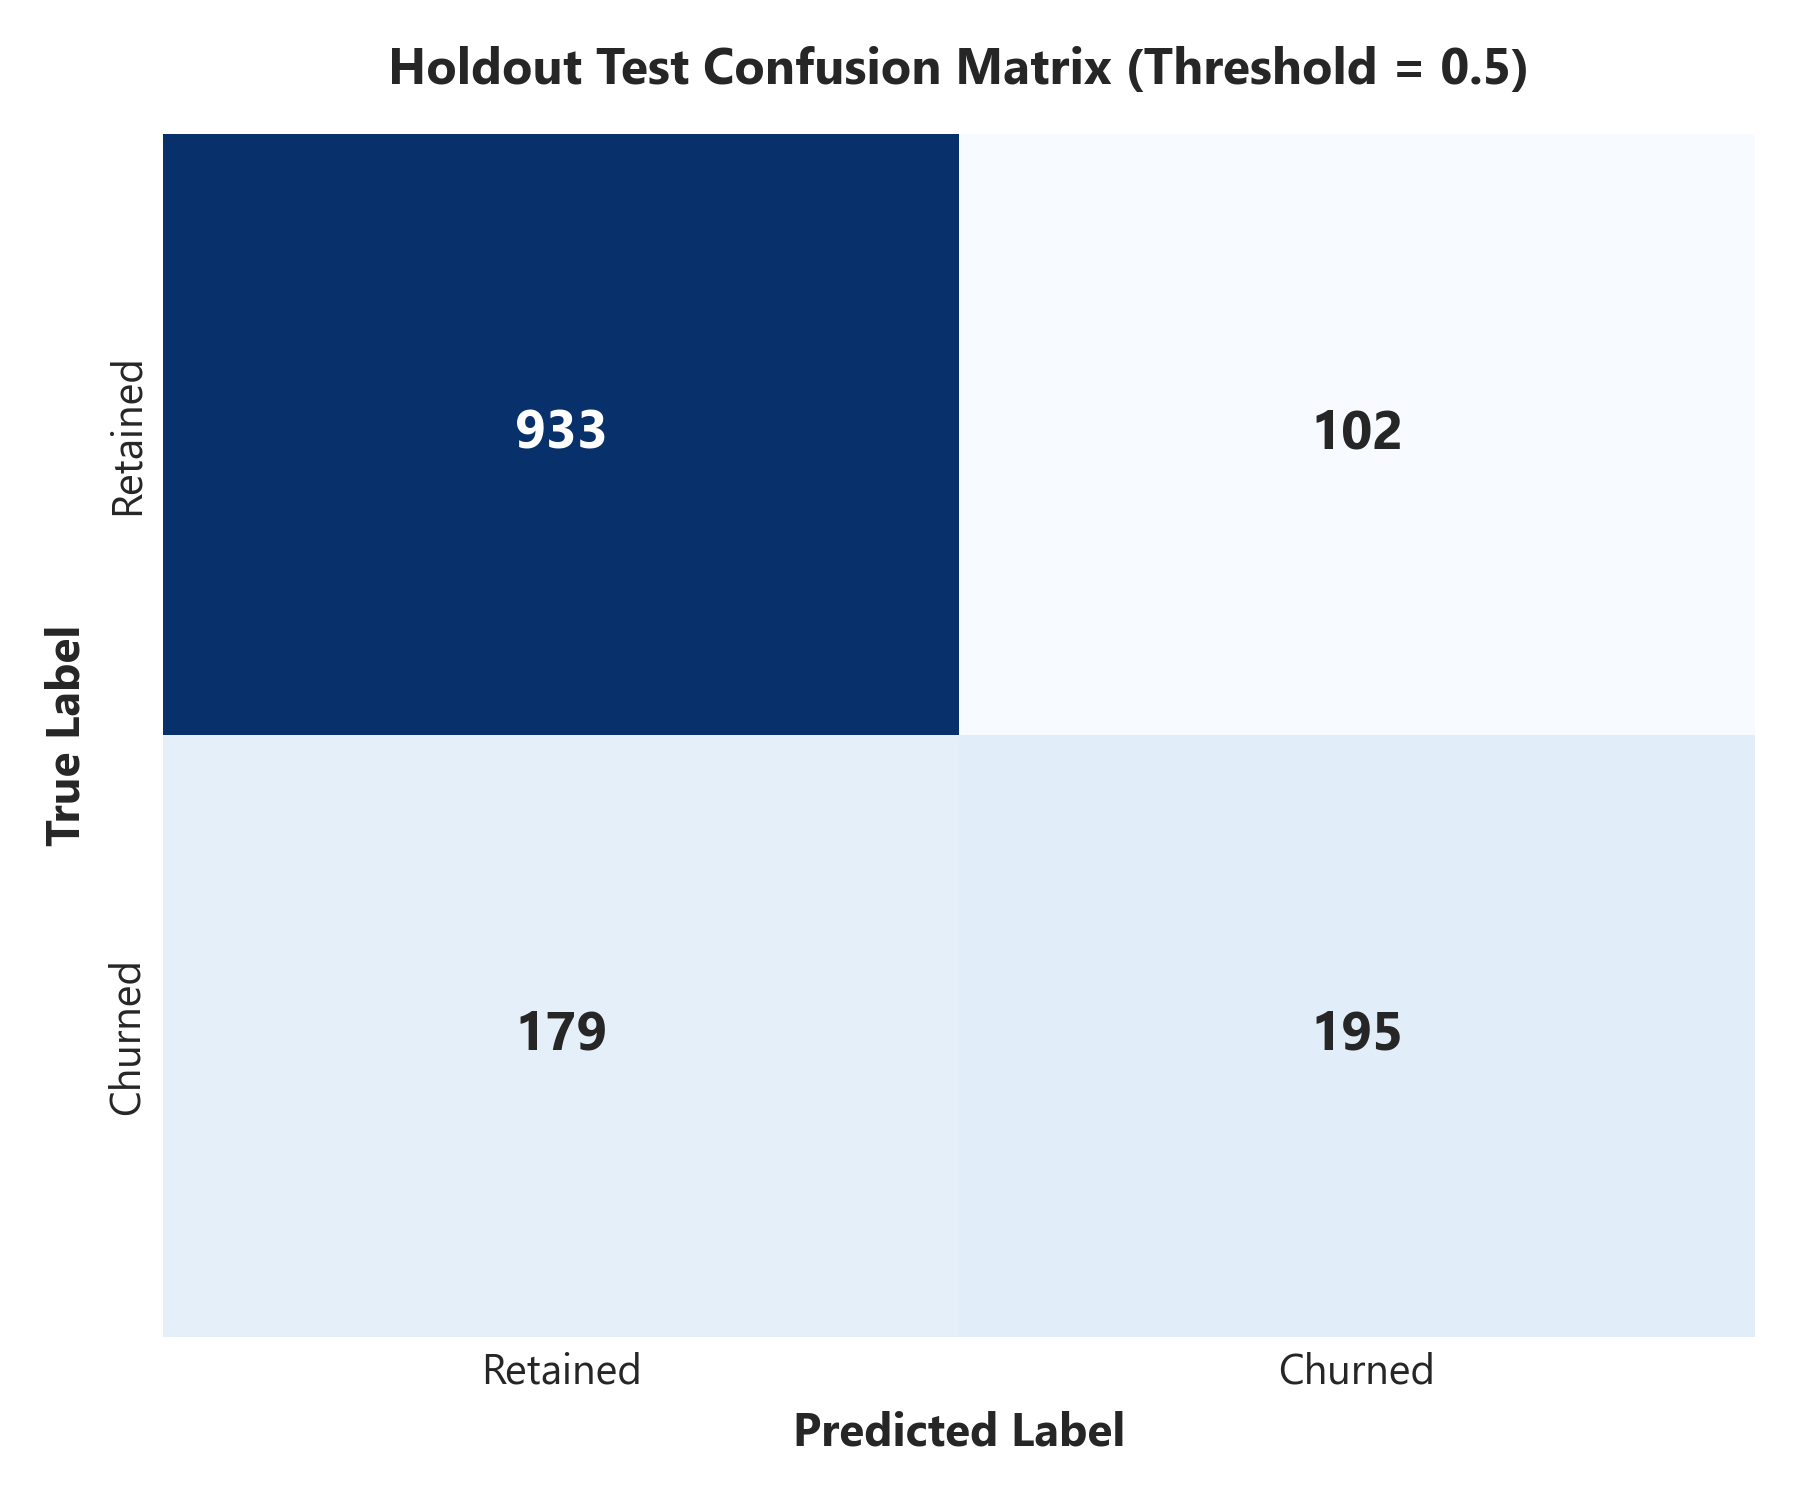

In [10]:
display(Image(filename=str(figures_dir / "19_holdout_roc_pr_curves.png")))
display(Image(filename=str(figures_dir / "20_holdout_confusion_matrix.png")))

## 6. Top Feature Importances & Model Artifact Verification

We inspect the top 20 predictive features in the final fitted model (impurity-based importances) and verify artifact integrity.

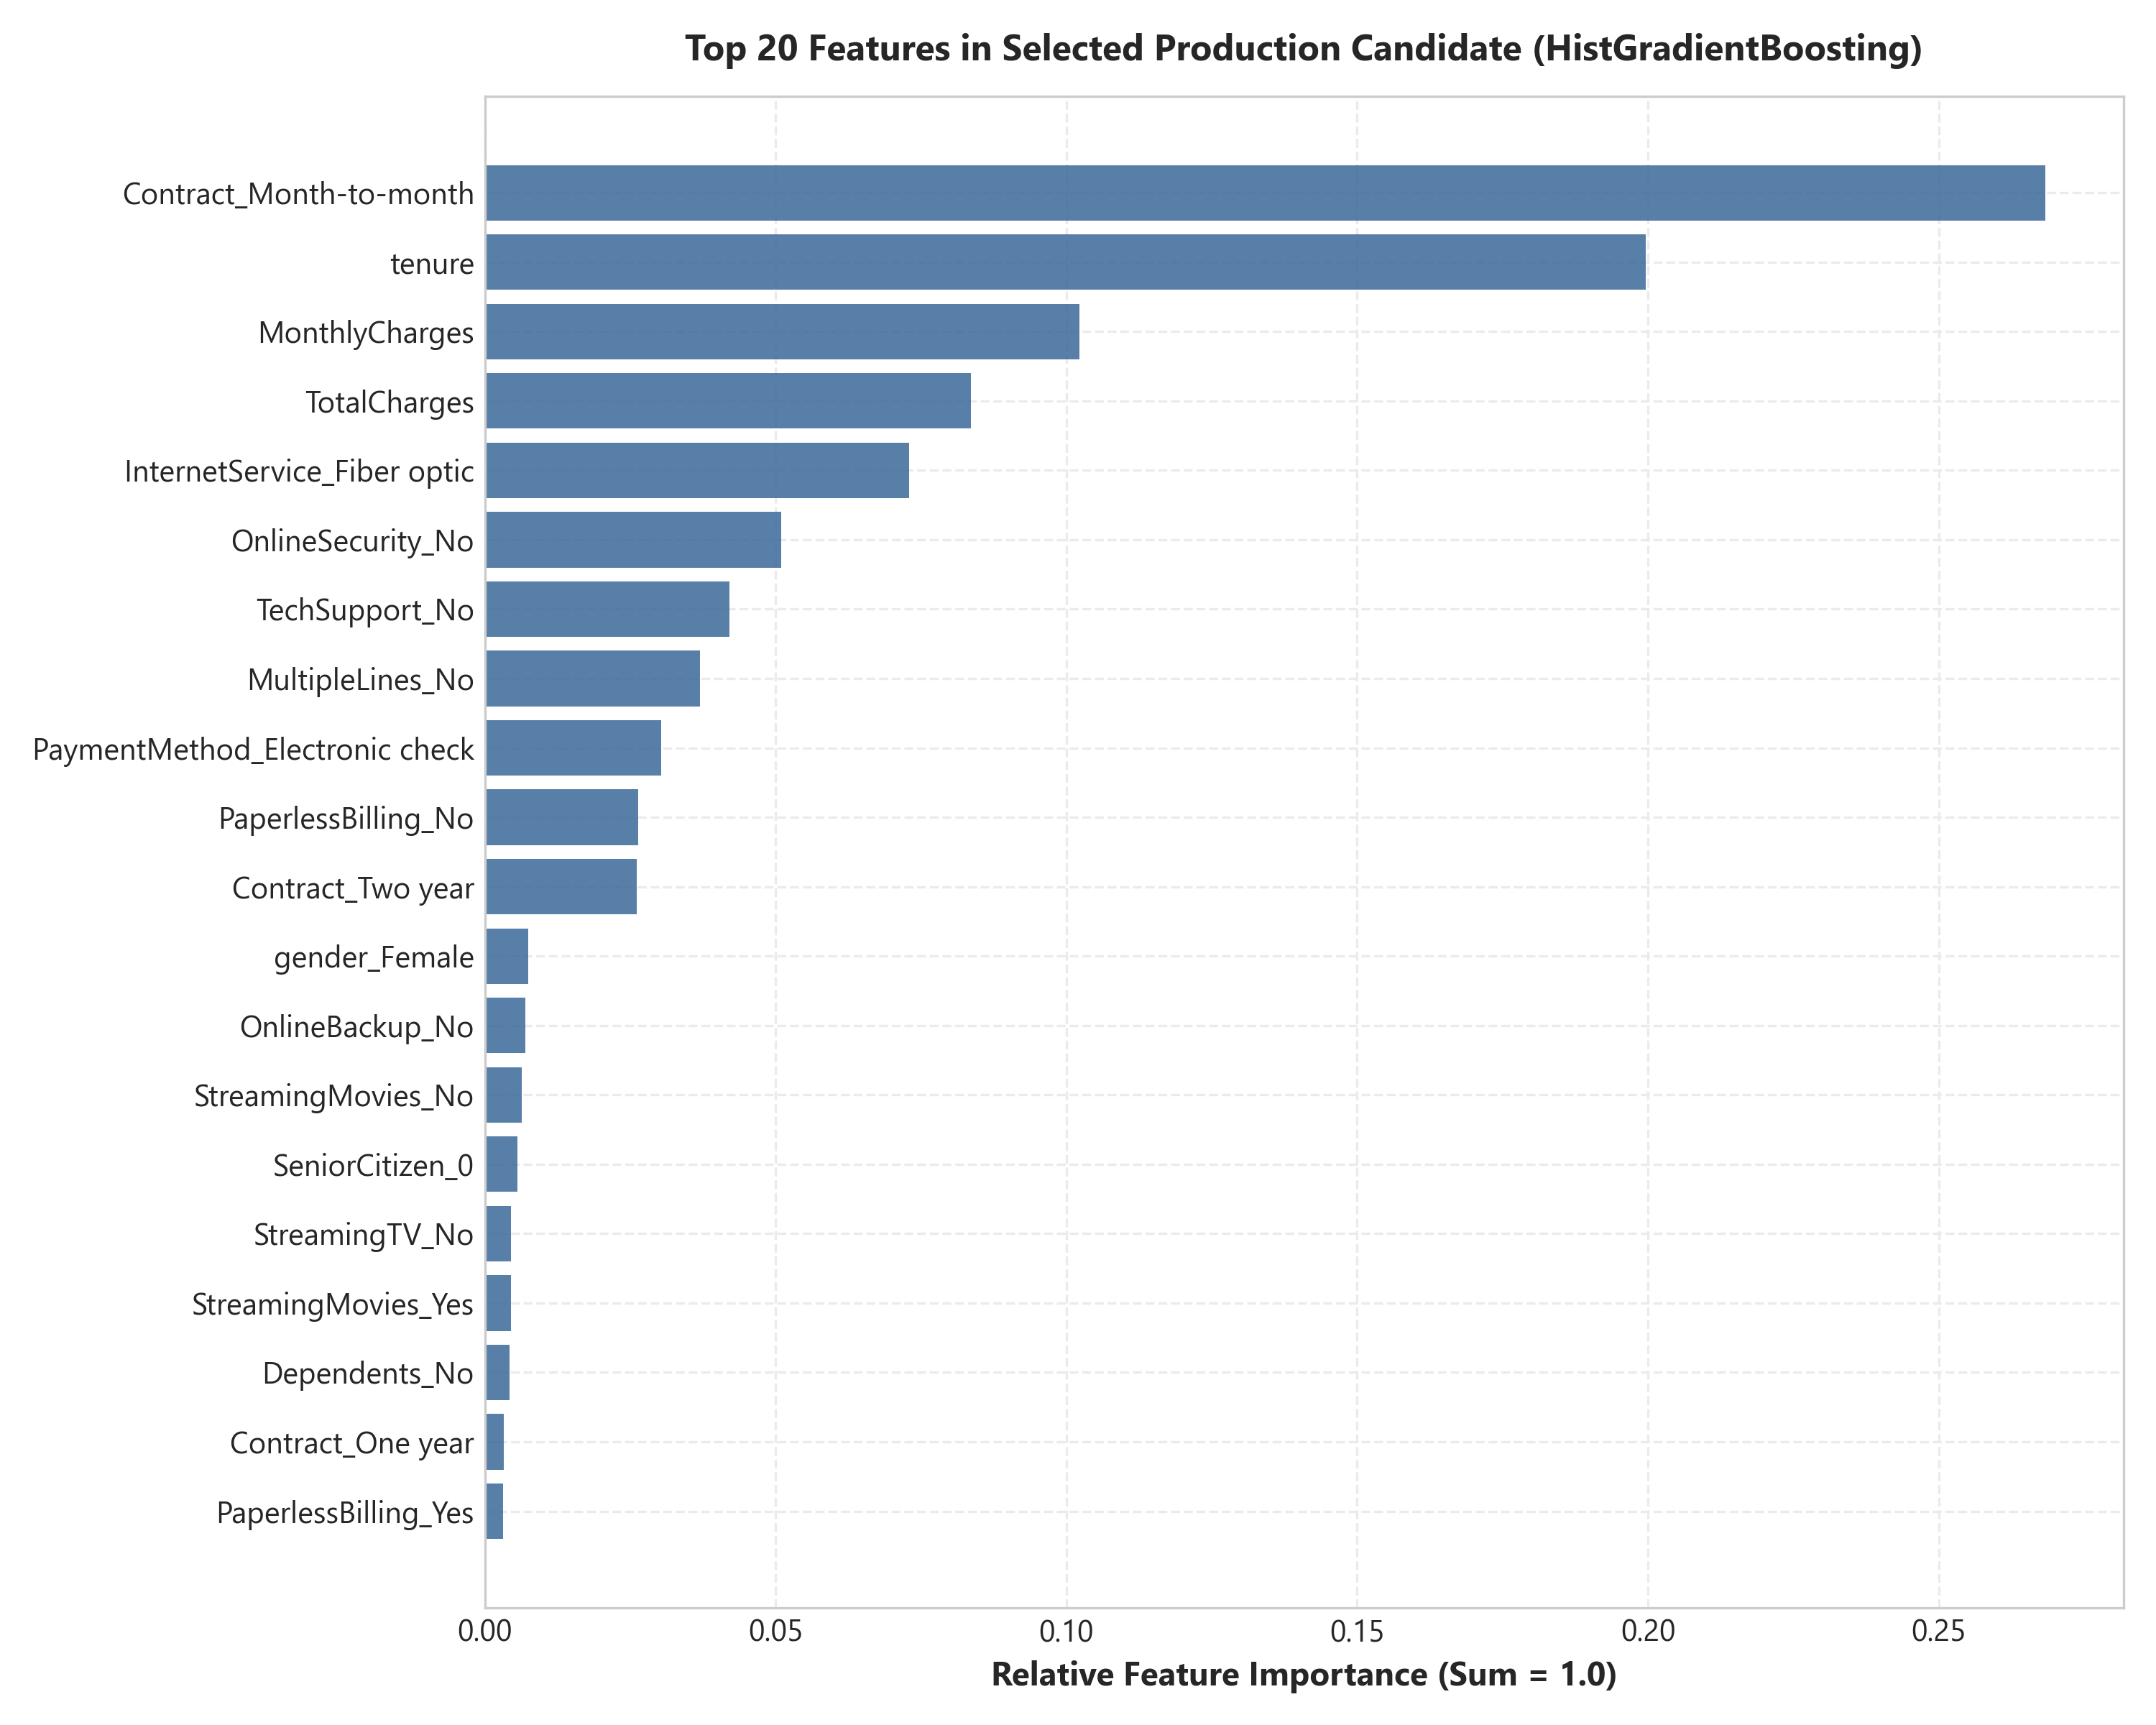

In [11]:
display(Image(filename=str(figures_dir / "21_feature_importances_top20.png")))

In [12]:
artifact_bundle = load_model_artifact(artifacts_dir / "model.joblib")
meta = artifact_bundle["metadata"]

print("Model Artifact Verification:")
print(f"  Model Family:      {meta['model_family']}")
print(f"  Feature Count:     {meta['feature_count']} features")
print(f"  Dataset SHA-256:   {meta['dataset_sha256'][:16]}...")
print(f"  Saved Timestamp:   {meta['saved_at_utc']}")
print(f"  Scikit-Learn Ver:  {meta['environment']['scikit_learn_version']}")

Model Artifact Verification:
  Model Family:      HistGradientBoostingClassifier
  Feature Count:     47 features
  Dataset SHA-256:   16320c9c1ec72448...
  Saved Timestamp:   2026-11-07T09:51:57.729999+00:00
  Scikit-Learn Ver:  1.6.1
